<img src="https://iddigitalschool.com/wp-content/uploads/2024/03/UCJC-Horizontal_Granate.png" alt="Universidad Camilo José Cela" width="300">

# Laboratorio 2: Análisis exploratorio, limpieza y preparación de conjuntos de datos reales para identificar patrones y extraer información relevante

**Programación Avanzada y Entornos de Desarrollo para la IA**

Objetivo: revisar la calidad de un conjunto de datos, limpiarlo y transformarlo, explorarlo para encontrar patrones y dejarlo preparado para entrenar un modelo.

**Tienes libertad para elegir las librerías** (pandas, Polars, DuckDB, Matplotlib, Seaborn, Plotly, scikit-learn…) y las decisiones de limpieza que tomes. No hay una única solución correcta: lo importante es que **justifiques cada decisión** con lo que ves en los datos y expliques qué has usado y por qué (paso 7).

Estructura propuesta:

| Paso | Qué haremos | Relación con el temario |
|---|---|---|
| 1 | Preparar el entorno | Tema 1: entornos y dependencias |
| 2 | Cargar los datos y primer vistazo | Carga de datos y tipos |
| 3 | Diagnóstico de calidad | Calidad de datos: nulos, duplicados, rangos, coherencia, atípicos |
| 4 | Limpieza y transformación | Tipos, codificación, variables derivadas |
| 5 | Análisis exploratorio | Estadística descriptiva y visualización |
| 6 | Preparación para modelado | Codificación, escalado y partición train/test |
| 7 | Librerías, reflexión y entrega | Git y asistentes de programación |

Datos: `data/raw/personal_spending_dataset.csv`, un conjunto de 10 000 personas con información demográfica, ingresos, gastos mensuales por categoría, deuda y hábitos financieros. Procede del conjunto [Personal Expense Data](https://www.kaggle.com/datasets/sanjay3454chauhan/personal-expense-data) de Kaggle.

## 1. Preparar el entorno

Crea una carpeta para el proyecto, por ejemplo con esta estructura:

```
lab2-personal-spending/
├── README.md
├── requirements.txt
├── lab2_gastos_personales-solved.ipynb
├── data/
│   ├── raw/
│   │   └── personal_spending_dataset.csv
│   └── processed/
└── src/
    ├── lab2_gastos_personales.ipynb
    └── app_shiny.py
```

Este notebook está en la raíz del proyecto. Las rutas se detectan a partir de la carpeta de ejecución y sus carpetas superiores.

Pistas:
- Reutiliza lo que aprendiste en el Laboratorio 1: entorno virtual (`venv` o `uv`) y un `requirements.txt` con las librerías que uses.
- Puedes empezar, por ejemplo, con `pandas`, `matplotlib`, `seaborn` y `scikit-learn`, y cambiarlas por las que prefieras.
- Comprueba con `sys.executable` que el notebook usa el Python de tu entorno virtual.

In [1]:
import sys

import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

print('Python:', sys.version.split()[0])
print('Ejecutable:', sys.executable)  # debe apuntar a .venv
for lib in (np, pd, matplotlib, sns, sklearn):
    print(f'{lib.__name__}: {lib.__version__}')

Python: 3.12.7
Ejecutable: C:\Users\marin\Downloads\MasterIA\ucjc-lab2-personal-expenses-activity-main\ucjc-lab2-personal-expenses-activity-main\.venv\Scripts\python.exe
numpy: 2.5.5
pandas: 3.1.1
matplotlib: 3.11.2
seaborn: 0.13.2
sklearn: 1.9.1


## 2. Cargar los datos y primer vistazo

Carga el CSV y revisa su estructura: número de filas y columnas, tipos de cada columna y estadísticos básicos.

Diccionario de variables (interpretación a partir de los nombres; el origen no documenta las unidades ni la moneda):

| Columna | Descripción |
|---|---|
| `age` | Edad en años |
| `gender` | Género |
| `occupation` | Ocupación: Employee, Freelancer, Business, Student, Unemployed |
| `city` | Tipo de zona de residencia: Urban, Suburban, Rural |
| `monthly_income` | Ingreso mensual |
| `income_source` | Fuente principal de ingresos: Salary, Business, Freelance, Multiple |
| `savings_rate` | Proporción del ingreso que se ahorra (0 = nada, 1 = todo) |
| `debt` | Deuda total acumulada |
| `housing_expense` … `healthcare_expense` | Gasto mensual en vivienda, comida, transporte, ocio, compras y salud |
| `credit_card_usage` | Uso de la tarjeta de crédito: Low, Medium, High |
| `investment` | Si tiene inversiones: Yes / No |
| `emergency_fund` | Si tiene fondo de emergencia: Yes / No |
| `financial_stress` | Nivel de estrés financiero declarado: Low, Medium, High |
| `financial_health_score` | Puntuación de salud financiera (cuanto más alta, mejor) |

Pista: piensa qué representa cada fila y si los tipos que detecta la librería son los adecuados para cada columna.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt

ubicacion = Path.cwd().resolve()
PROYECTO = next(
    (carpeta for carpeta in (ubicacion, *ubicacion.parents)
     if (carpeta / 'data' / 'raw' / 'personal_spending_dataset.csv').is_file()),
    None,
)
if PROYECTO is None:
    raise FileNotFoundError('No se encuentra el CSV. Ejecuta el notebook desde la carpeta del proyecto.')

RUTA_RAW = PROYECTO / 'data' / 'raw' / 'personal_spending_dataset.csv'
RUTA_PROCESSED = PROYECTO / 'data' / 'processed' / 'gastos_limpio.csv'
DIR_MODELADO = PROYECTO / 'data' / 'processed' / 'modelado'

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

df_raw = pd.read_csv(RUTA_RAW)
print('Filas:', len(df_raw), '· Columnas:', df_raw.shape[1])
df_raw.head()

Filas: 10000 · Columnas: 19


,age,gender,occupation,city,monthly_income,income_source,savings_rate,debt,housing_expense,food_expense,transport_expense,entertainment_expense,shopping_expense,healthcare_expense,credit_card_usage,investment,emergency_fund,financial_stress,financial_health_score
0,39,Male,Freelancer,Suburban,1838.091952,Freelance,0.352595,16974.033664,615.006324,251.613540,103.204823,124.108756,156.525199,133.607007,High,No,No,Low,11.982524
1,63,Male,Employee,Urban,2120.258854,Salary,0.299926,6173.596466,602.728817,211.883811,183.940097,141.427418,77.341012,147.922543,Medium,No,Yes,High,15.241101
2,55,Male,Employee,Rural,2241.629191,Salary,0.226699,12100.266553,811.439669,251.596580,195.942203,200.597172,143.466202,52.837494,Medium,No,Yes,High,6.712623
3,49,Female,Freelancer,Urban,2209.439558,Salary,0.000000,793.561779,562.361587,253.801974,165.078795,248.258432,124.024830,51.684896,Medium,Yes,Yes,High,5.076121
4,28,Male,Employee,Suburban,1767.891180,Salary,0.162211,3607.481984,635.962795,179.252144,155.290092,197.464810,131.330689,127.109756,Medium,Yes,Yes,Medium,34.106650


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     10000 non-null  int64  
 1   gender                  10000 non-null  str    
 2   occupation              10000 non-null  str    
 3   city                    10000 non-null  str    
 4   monthly_income          10000 non-null  float64
 5   income_source           10000 non-null  str    
 6   savings_rate            10000 non-null  float64
 7   debt                    10000 non-null  float64
 8   housing_expense         10000 non-null  float64
 9   food_expense            10000 non-null  float64
 10  transport_expense       10000 non-null  float64
 11  entertainment_expense   10000 non-null  float64
 12  shopping_expense        10000 non-null  float64
 13  healthcare_expense      10000 non-null  float64
 14  credit_card_usage       10000 non-null  str    
 1

In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,10000.0,43.41,13.27,18.00,33.00,45.00,55.00,64.00
monthly_income,10000.0,2754.88,1462.05,261.70,1720.34,2435.22,3412.78,15739.31
savings_rate,10000.0,0.20,0.10,0.00,0.13,0.20,0.27,0.57
debt,10000.0,4967.62,6269.34,46.63,1530.06,3061.87,5947.85,98234.54
housing_expense,10000.0,893.65,493.72,70.40,548.89,781.12,1111.23,4406.96
food_expense,10000.0,316.83,179.80,32.34,191.43,275.03,393.37,1808.45
transport_expense,10000.0,206.69,118.24,13.64,123.62,179.07,257.52,1256.32
entertainment_expense,10000.0,204.77,133.67,15.30,110.79,171.07,262.14,1489.32
shopping_expense,10000.0,179.56,113.14,13.35,100.44,150.35,229.80,1320.47
healthcare_expense,10000.0,138.81,90.86,8.05,75.07,116.32,178.06,906.17


## 3. Diagnóstico de calidad

Antes de limpiar hay que saber qué falla. Un conjunto sin valores nulos no es necesariamente un conjunto limpio.

Revisa, como mínimo:
- **Nulos y duplicados.**
- **Categorías**: valores escritos de varias formas, espacios, mayúsculas, categorías inesperadas.
- **Rangos**: valores negativos, proporciones fuera de [0, 1], edades imposibles, valores exactamente 0 que puedan esconder datos recortados o ausentes.
- **Coherencia entre columnas**: ¿la suma de los gastos más el ahorro cabe en el ingreso? ¿La ocupación encaja con la fuente de ingresos?
- **Valores atípicos**: usa por ejemplo el criterio del rango intercuartílico (IQR) y la asimetría de cada variable numérica, y represéntalos con un diagrama de caja.

Pista: anota cada problema que encuentres; en el paso 4 tendrás que decidir qué haces con él.

### 3.1 Nulos y duplicados

In [5]:
nulos = df_raw.isna().sum()
print('Columnas con nulos:', nulos[nulos > 0].to_dict() or 'ninguna')
print('Filas duplicadas:', df_raw.duplicated().sum())

Columnas con nulos: ninguna
Filas duplicadas: 0


### 3.2 Categorías

In [6]:
COLUMNAS_CATEGORICAS = df_raw.select_dtypes(exclude='number').columns.tolist()

for col in COLUMNAS_CATEGORICAS:
    valores = df_raw[col]
    # si al normalizar espacios y mayúsculas hay menos valores distintos, hay variantes de la misma categoría
    variantes = valores.nunique() != valores.str.strip().str.lower().nunique()
    print(f'{col}: {valores.value_counts().to_dict()}' + ('  <- variantes de escritura' if variantes else ''))

gender: {'Female': 5257, 'Male': 4743}
occupation: {'Employee': 4484, 'Freelancer': 1580, 'Student': 1489, 'Business': 1459, 'Unemployed': 988}
city: {'Urban': 5000, 'Suburban': 3010, 'Rural': 1990}
income_source: {'Salary': 5990, 'Business': 1521, 'Freelance': 1496, 'Multiple': 993}
credit_card_usage: {'Medium': 4983, 'Low': 3007, 'High': 2010}
investment: {'No': 5538, 'Yes': 4462}
emergency_fund: {'No': 5000, 'Yes': 5000}
financial_stress: {'Medium': 4982, 'Low': 2946, 'High': 2072}


### 3.3 Rangos y valores en cero

In [7]:
COLUMNAS_NUMERICAS = df_raw.select_dtypes('number').columns.tolist()
COLUMNAS_GASTO = [c for c in df_raw.columns if c.endswith('_expense')]

print('Valores negativos:', int((df_raw[COLUMNAS_NUMERICAS] < 0).sum().sum()))
print('savings_rate fuera de [0, 1]:', int((~df_raw['savings_rate'].between(0, 1)).sum()))
print('Edad mínima y máxima:', df_raw['age'].min(), '-', df_raw['age'].max())

ceros = (df_raw[COLUMNAS_NUMERICAS] == 0).sum()
print('Valores exactamente 0:', ceros[ceros > 0].to_dict())

Valores negativos: 0
savings_rate fuera de [0, 1]: 0
Edad mínima y máxima: 18 - 64
Valores exactamente 0: {'savings_rate': 246, 'financial_health_score': 528}


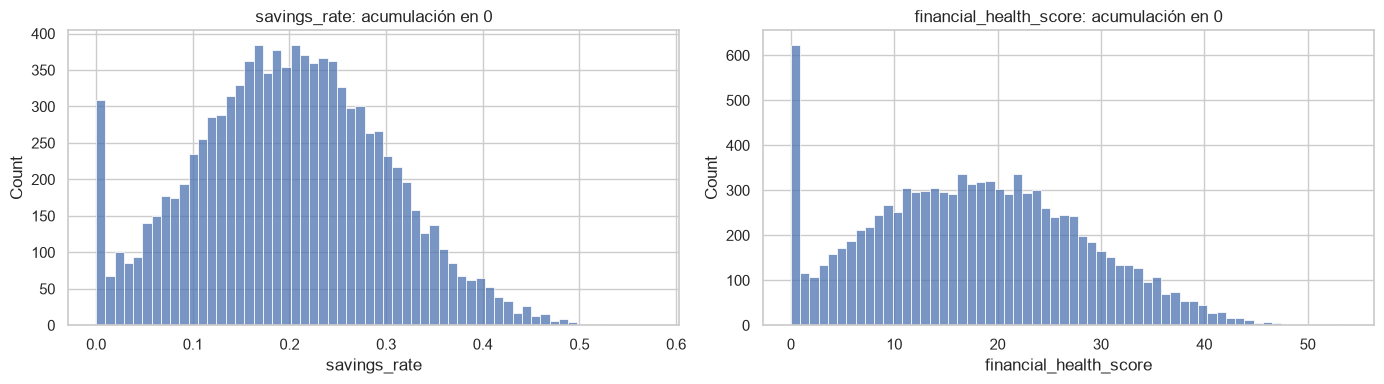

In [8]:
# ¿Los ceros son valores reales o un recorte? Si hubiera muchos valores cerca de 0, la distribución bajaría suave hasta él
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_raw['savings_rate'], bins=60, ax=ejes[0])
ejes[0].set_title('savings_rate: acumulación en 0')
sns.histplot(df_raw['financial_health_score'], bins=60, ax=ejes[1])
ejes[1].set_title('financial_health_score: acumulación en 0')
plt.tight_layout()
plt.show()

### 3.4 Coherencia entre columnas

In [9]:
gasto_total = df_raw[COLUMNAS_GASTO].sum(axis=1)
ahorro_mensual = df_raw['savings_rate'] * df_raw['monthly_income']
supera_ingreso = gasto_total + ahorro_mensual > df_raw['monthly_income']
print(f'Gasto + ahorro supera el ingreso: {supera_ingreso.sum()} filas ({supera_ingreso.mean():.1%})')

desempleado_con_salario = df_raw['occupation'].eq('Unemployed') & df_raw['income_source'].eq('Salary')
print(f'Desempleados cuya fuente de ingresos es un salario: {desempleado_con_salario.sum()} filas')

estudiante_mayor = df_raw['occupation'].eq('Student') & (df_raw['age'] >= 50)
print(f'Estudiantes de 50 años o más: {estudiante_mayor.sum()} filas')

pd.crosstab(df_raw['occupation'], df_raw['income_source'], margins=True)

Gasto + ahorro supera el ingreso: 2112 filas (21.1%)
Desempleados cuya fuente de ingresos es un salario: 602 filas
Estudiantes de 50 años o más: 571 filas


income_source,Business,Freelance,Multiple,Salary,All
occupation,,,,,
Business,229,197,157,876,1459
Employee,666,670,449,2699,4484
Freelancer,256,258,157,909,1580
Student,231,216,138,904,1489
Unemployed,139,155,92,602,988
All,1521,1496,993,5990,10000


### 3.5 Valores atípicos

In [10]:
def contar_atipicos_iqr(serie, k=1.5):
    '''Cuenta los valores fuera de [Q1 - k·IQR, Q3 + k·IQR].'''
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - k * iqr) | (serie > q3 + k * iqr)).sum())


atipicos = pd.DataFrame({
    'atipicos_iqr': {col: contar_atipicos_iqr(df_raw[col]) for col in COLUMNAS_NUMERICAS},
    'asimetria': df_raw[COLUMNAS_NUMERICAS].skew(),
    'maximo': df_raw[COLUMNAS_NUMERICAS].max(),
    'mediana': df_raw[COLUMNAS_NUMERICAS].median(),
}).round(2)
atipicos.sort_values('atipicos_iqr', ascending=False)

,atipicos_iqr,asimetria,maximo,mediana
debt,753,4.62,98234.54,3061.87
entertainment_expense,414,1.79,1489.32,171.07
healthcare_expense,408,1.77,906.17,116.32
transport_expense,403,1.72,1256.32,179.07
food_expense,400,1.79,1808.45,275.03
shopping_expense,384,1.82,1320.47,150.35
monthly_income,378,1.67,15739.31,2435.22
housing_expense,378,1.71,4406.96,781.12
savings_rate,24,0.10,0.57,0.20
financial_health_score,9,0.18,53.73,17.52


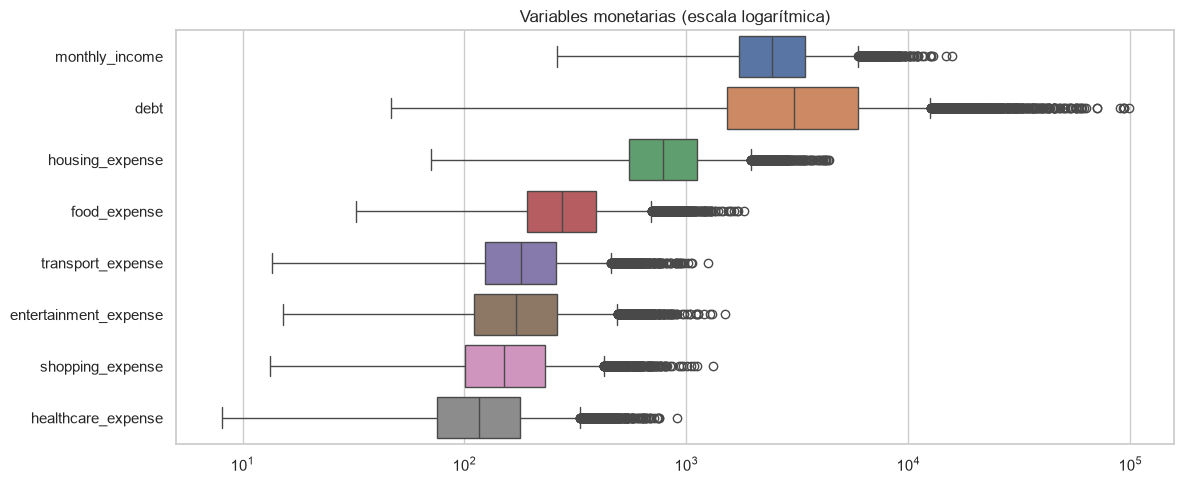

In [11]:
COLUMNAS_DINERO = ['monthly_income', 'debt', *COLUMNAS_GASTO]

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df_raw[COLUMNAS_DINERO], orient='h', ax=ax)
ax.set_xscale('log')
ax.set_title('Variables monetarias (escala logarítmica)')
plt.tight_layout()
plt.show()

**Diagnóstico (ejemplo):**

| Problema | Filas afectadas | Decisión (paso 4) |
|---|---|---|
| Nulos y duplicados | 0 | Nada que hacer |
| Variantes de escritura en las categorías | 0 | Nada que hacer |
| La columna `city` no contiene ciudades sino el tipo de zona | todas | Renombrar a `area` |
| `Yes`/`No` y `Low`/`Medium`/`High` guardados como texto | todas | Booleanos y categorías ordenadas |
| Gasto + ahorro supera el ingreso | 2112 (21,1 %) | Marcar con `flag_over_budget`; eliminar 1 de cada 5 filas sesgaría el análisis |
| Desempleados con salario como fuente de ingresos | 602 | Marcar con `flag_unemployed_salary` |
| Estudiantes de 50 años o más | 571 | Se mantienen: es posible, pero la proporción de estudiantes es igual en todas las edades. Se comenta como limitación |
| `financial_health_score` exactamente 0, con un pico aislado en el histograma | 528 | Parecen valores recortados a 0 (la puntuación real sería negativa); se marcan con `flag_score_clipped` |
| `savings_rate` exactamente 0 | 246 | Se mantienen: no ahorrar nada es un valor posible |
| Variables monetarias muy sesgadas a la derecha (asimetría 1,7 a 4,6) con cientos de atípicos IQR | hasta 753 (`debt`) | Se mantienen: son extremos posibles (ingresos o deudas altas), no errores. Se usa escala logarítmica en gráficos y `log1p` al preparar para modelado |

## 4. Limpieza y transformación

Aplica las decisiones que hayas tomado en el diagnóstico. Ideas:
- **Tipos**: categorías como tipo categórico (ordenado cuando tenga sentido, como Low < Medium < High) y `Yes`/`No` como booleanos.
- **Nombres**: renombra las columnas cuyo nombre no describa bien su contenido.
- **Variables derivadas**: gasto total, proporción del ingreso que se gasta, ahorro mensual, deuda respecto al ingreso anual, grupos de edad…
- **Problemas detectados**: decide si eliminas, corriges o marcas (por ejemplo con una columna `flag_...`) las filas problemáticas. Ten en cuenta cuántas filas afecta cada decisión.
- **Atípicos**: decide si son errores o valores extremos pero posibles, y si los mantienes, los recortas o transformas la variable (por ejemplo con un logaritmo).

Explica en una celda markdown cada decisión y por qué la has tomado.

### 4.1 Tipos y nombres

In [12]:
NIVELES = ['Low', 'Medium', 'High']
SI_NO = {'Yes': True, 'No': False}

df = (
    df_raw
    .rename(columns={'city': 'area'})
    .assign(
        gender=lambda d: d['gender'].astype('category'),
        occupation=lambda d: d['occupation'].astype('category'),
        area=lambda d: pd.Categorical(d['area'], categories=['Rural', 'Suburban', 'Urban']),
        income_source=lambda d: d['income_source'].astype('category'),
        credit_card_usage=lambda d: pd.Categorical(d['credit_card_usage'], categories=NIVELES, ordered=True),
        financial_stress=lambda d: pd.Categorical(d['financial_stress'], categories=NIVELES, ordered=True),
        investment=lambda d: d['investment'].map(SI_NO),
        emergency_fund=lambda d: d['emergency_fund'].map(SI_NO),
    )
)

# comprobaciones: no se ha perdido ninguna fila ni se han creado nulos al convertir
assert len(df) == len(df_raw)
assert df.notna().all().all(), 'Algún valor no encaja con las categorías esperadas'
df.dtypes

age                          int64
gender                    category
occupation                category
area                      category
monthly_income             float64
income_source             category
savings_rate               float64
debt                       float64
housing_expense            float64
food_expense               float64
transport_expense          float64
entertainment_expense      float64
shopping_expense           float64
healthcare_expense         float64
credit_card_usage         category
investment                    bool
emergency_fund                bool
financial_stress          category
financial_health_score     float64
dtype: object

### 4.2 Variables derivadas y marcas de calidad

In [13]:
df = df.assign(
    total_expense=df[COLUMNAS_GASTO].sum(axis=1),
    expense_ratio=lambda d: d['total_expense'] / d['monthly_income'],
    monthly_savings=lambda d: d['savings_rate'] * d['monthly_income'],
    debt_to_annual_income=lambda d: d['debt'] / (12 * d['monthly_income']),
    age_group=pd.cut(df['age'], bins=[17, 25, 35, 45, 55, 64], labels=['18-25', '26-35', '36-45', '46-55', '56-64']),
    # marcas de calidad: no se eliminan filas, pero quedan identificadas
    flag_over_budget=lambda d: d['total_expense'] + d['monthly_savings'] > d['monthly_income'],
    flag_unemployed_salary=lambda d: d['occupation'].eq('Unemployed') & d['income_source'].eq('Salary'),
    flag_score_clipped=lambda d: d['financial_health_score'].eq(0),
)

COLUMNAS_FLAG = [c for c in df.columns if c.startswith('flag_')]
print(df[COLUMNAS_FLAG].sum())
print('Filas con al menos una marca:', df[COLUMNAS_FLAG].any(axis=1).sum())
df.head()

flag_over_budget          2112
flag_unemployed_salary     602
flag_score_clipped         528
dtype: int64
Filas con al menos una marca: 3081


,age,gender,occupation,area,monthly_income,income_source,savings_rate,debt,housing_expense,food_expense,transport_expense,entertainment_expense,shopping_expense,healthcare_expense,credit_card_usage,investment,emergency_fund,financial_stress,financial_health_score,total_expense,expense_ratio,monthly_savings,debt_to_annual_income,age_group,flag_over_budget,flag_unemployed_salary,flag_score_clipped
0,39,Male,Freelancer,Suburban,1838.091952,Freelance,0.352595,16974.033664,615.006324,251.613540,103.204823,124.108756,156.525199,133.607007,High,False,False,Low,11.982524,1384.065648,0.752990,648.101639,0.769550,36-45,True,False,False
1,63,Male,Employee,Urban,2120.258854,Salary,0.299926,6173.596466,602.728817,211.883811,183.940097,141.427418,77.341012,147.922543,Medium,False,True,High,15.241101,1365.243697,0.643904,635.921776,0.242643,56-64,False,False,False
2,55,Male,Employee,Rural,2241.629191,Salary,0.226699,12100.266553,811.439669,251.596580,195.942203,200.597172,143.466202,52.837494,Medium,False,True,High,6.712623,1655.879320,0.738695,508.176072,0.449832,46-55,False,False,False
3,49,Female,Freelancer,Urban,2209.439558,Salary,0.000000,793.561779,562.361587,253.801974,165.078795,248.258432,124.024830,51.684896,Medium,True,True,High,5.076121,1405.210512,0.636003,0.000000,0.029931,46-55,False,False,False
4,28,Male,Employee,Suburban,1767.891180,Salary,0.162211,3607.481984,635.962795,179.252144,155.290092,197.464810,131.330689,127.109756,Medium,True,True,Medium,34.106650,1426.410285,0.806843,286.771898,0.170046,26-35,False,False,False


**Decisiones (ejemplo):**
- No se elimina ninguna fila. Las inconsistencias afectan a más del 20 % de los datos y no sabemos cuál es el valor correcto, así que se marcan con columnas `flag_` para poder filtrarlas o compararlas.
- Los atípicos se mantienen: ingresos de 15 000 o deudas de 98 000 son extremos pero posibles. Se tratan con escala logarítmica en los gráficos.
- `city` pasa a llamarse `area`, porque contiene tipos de zona y no ciudades.
- Las variables `Low`/`Medium`/`High` se guardan como categorías ordenadas para que los gráficos y la codificación respeten el orden.

## 5. Análisis exploratorio

Busca patrones en los datos limpios. Incluye al menos:
- La distribución de las variables principales (ingreso, ahorro, puntuación de salud financiera…).
- Cómo se reparte el gasto entre categorías, en valor absoluto y como proporción del ingreso.
- Las correlaciones entre variables numéricas.
- Comparaciones por grupos (ocupación, zona, edad, inversión, fondo de emergencia, estrés…).

Haz al menos cuatro gráficos. Puedes usar Matplotlib, Seaborn, Plotly, Altair…

### 5.1 Distribuciones

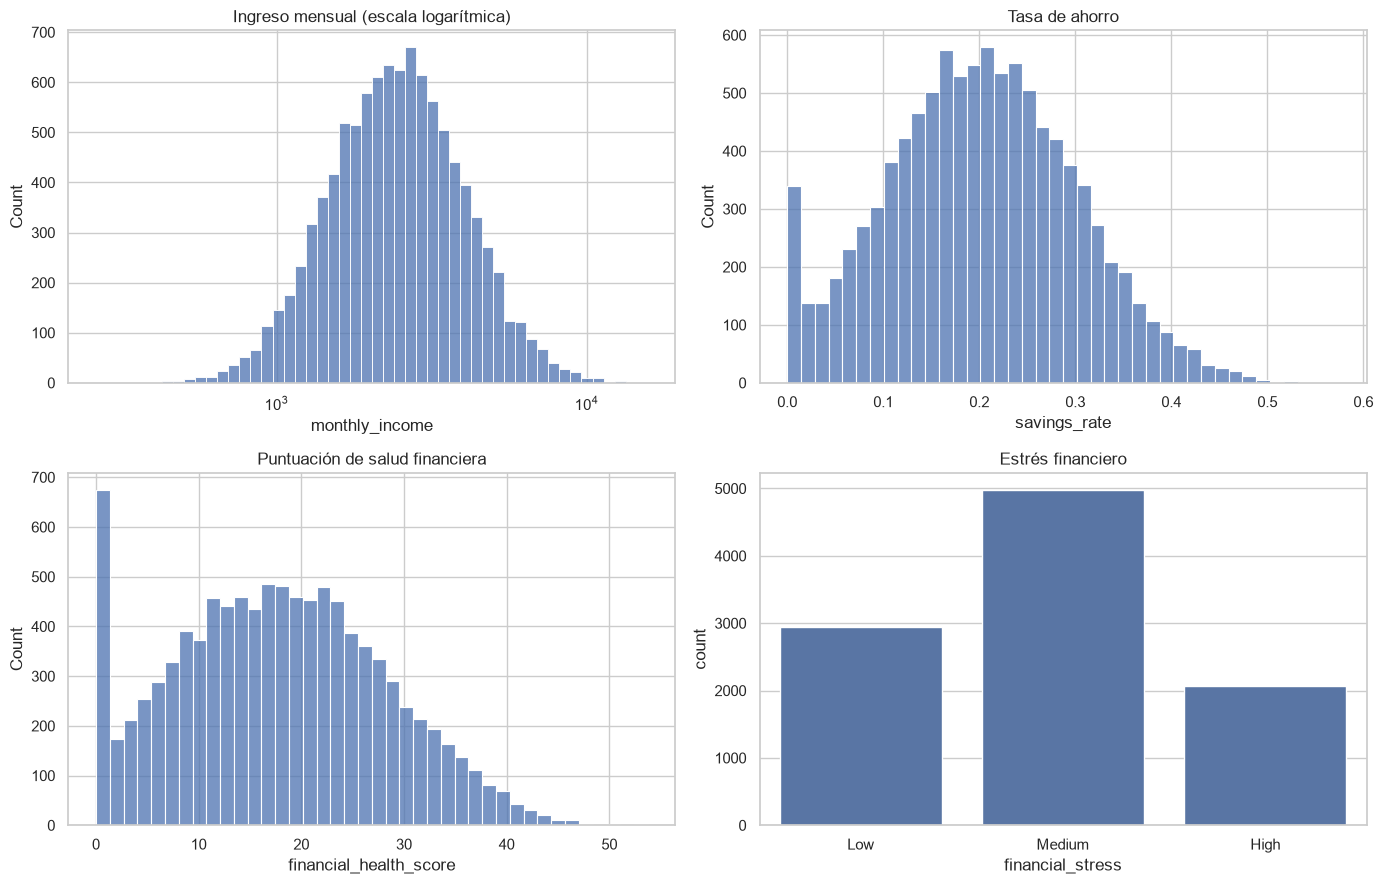

In [14]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df['monthly_income'], bins=50, log_scale=True, ax=ejes[0, 0])
ejes[0, 0].set_title('Ingreso mensual (escala logarítmica)')

sns.histplot(df['savings_rate'], bins=40, ax=ejes[0, 1])
ejes[0, 1].set_title('Tasa de ahorro')

sns.histplot(df['financial_health_score'], bins=40, ax=ejes[1, 0])
ejes[1, 0].set_title('Puntuación de salud financiera')

sns.countplot(x='financial_stress', data=df, ax=ejes[1, 1])
ejes[1, 1].set_title('Estrés financiero')

plt.tight_layout()
plt.show()

### 5.2 Composición del gasto

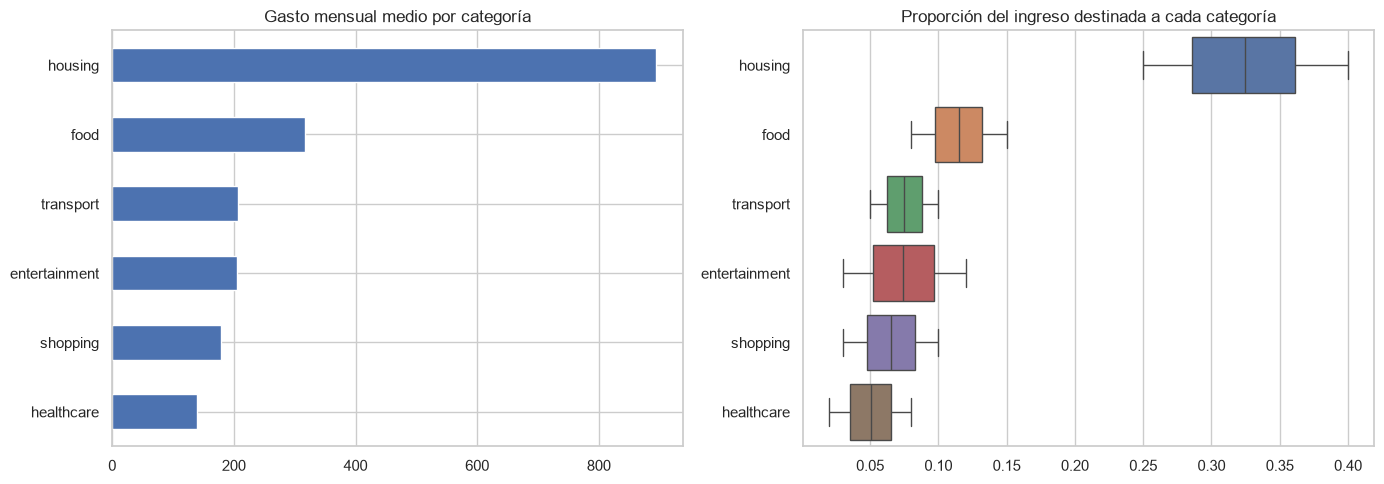

,min,mean,max
housing,0.25,0.324,0.40
food,0.08,0.115,0.15
transport,0.05,0.075,0.10
entertainment,0.03,0.074,0.12
shopping,0.03,0.065,0.10
healthcare,0.02,0.050,0.08


In [15]:
proporciones = (
    df[COLUMNAS_GASTO]
    .div(df['monthly_income'], axis=0)
    .rename(columns=lambda c: c.removesuffix('_expense'))
)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
df[COLUMNAS_GASTO].mean().rename(lambda c: c.removesuffix('_expense')).sort_values().plot.barh(ax=ejes[0])
ejes[0].set_title('Gasto mensual medio por categoría')
sns.boxplot(data=proporciones, orient='h', ax=ejes[1])
ejes[1].set_title('Proporción del ingreso destinada a cada categoría')
plt.tight_layout()
plt.show()

proporciones.describe().T[['min', 'mean', 'max']].round(3)

### 5.3 Correlaciones

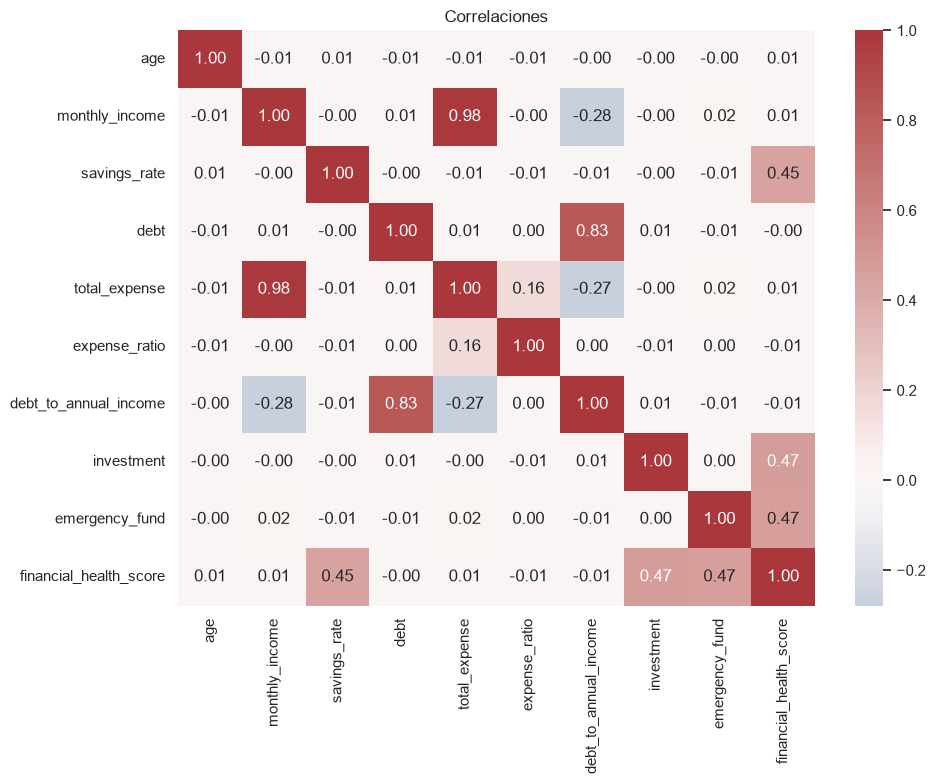

investment               0.471
emergency_fund           0.467
savings_rate             0.448
monthly_income           0.013
total_expense            0.010
age                      0.007
debt                    -0.002
expense_ratio           -0.009
debt_to_annual_income   -0.009
Name: financial_health_score, dtype: float64

In [16]:
COLUMNAS_CORR = [
    'age', 'monthly_income', 'savings_rate', 'debt', 'total_expense', 'expense_ratio',
    'debt_to_annual_income', 'investment', 'emergency_fund', 'financial_health_score',
]
correlaciones = df[COLUMNAS_CORR].astype(float).corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax)
ax.set_title('Correlaciones')
plt.tight_layout()
plt.show()

correlaciones['financial_health_score'].drop('financial_health_score').sort_values(ascending=False).round(3)

### 5.4 Comparación por grupos

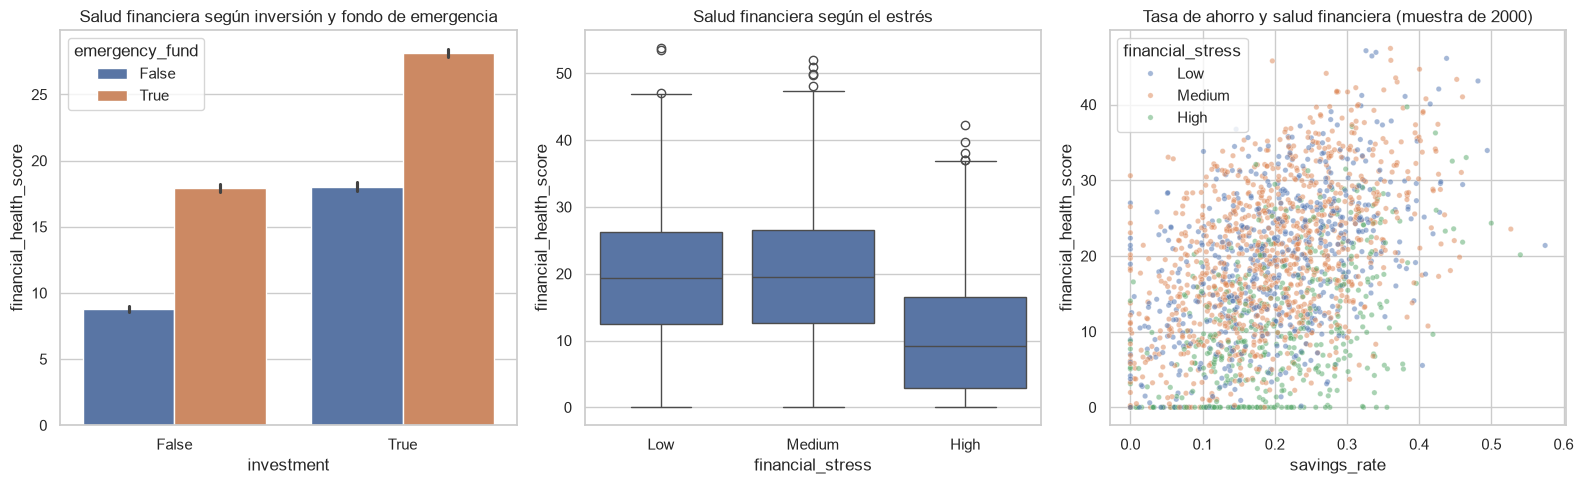

emergency_fund,False,True
investment,,
False,8.80,17.93
True,18.01,28.10


In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(x='investment', y='financial_health_score', hue='emergency_fund', data=df, ax=ejes[0])
ejes[0].set_title('Salud financiera según inversión y fondo de emergencia')

sns.boxplot(x='financial_stress', y='financial_health_score', data=df, ax=ejes[1])
ejes[1].set_title('Salud financiera según el estrés')

muestra = df.sample(2000, random_state=42)
sns.scatterplot(x='savings_rate', y='financial_health_score', hue='financial_stress', data=muestra, alpha=0.5, s=15, ax=ejes[2])
ejes[2].set_title('Tasa de ahorro y salud financiera (muestra de 2000)')

plt.tight_layout()
plt.show()

df.pivot_table(index='investment', columns='emergency_fund', values='financial_health_score', aggfunc='mean', observed=True).round(2)

In [18]:
resumen_por = {}
for grupo in ['occupation', 'area', 'age_group', 'income_source']:
    resumen_por[grupo] = df.groupby(grupo, observed=True).agg(
        personas=('age', 'size'),
        ingreso_mediano=('monthly_income', 'median'),
        ahorro_medio=('savings_rate', 'mean'),
        deuda_mediana=('debt', 'median'),
        salud_media=('financial_health_score', 'mean'),
    ).round(2)

pd.concat(resumen_por, names=['variable', 'grupo'])

personas  ingreso_mediano  ahorro_medio  \
variable      grupo                                                 
occupation    Business        1459          2414.21          0.20   
              Employee        4484          2429.35          0.20   
              Freelancer      1580          2484.83          0.20   
              Student         1489          2426.15          0.20   
              Unemployed       988          2462.33          0.19   
area          Rural           1990          2414.45          0.20   
              Suburban        3010          2436.13          0.20   
              Urban           5000          2445.99          0.20   
age_group     18-25           1255          2487.02          0.20   
              26-35           1818          2399.76          0.20   
              36-45           2164          2455.08          0.20   
              46-55           2402          2450.28          0.20   
              56-64           2361          2413.23          0.20   
income_source Business        1521          2392.78          0.20   
              Freelance       1496          2419.52          0.20   
              Multiple         993          2422.09          0.20   
              Salary          5990          2452.03          0.20   

                          deuda_mediana  salud_media  
variable      grupo                                   
occupation    Business          3063.39        17.79  
              Employee          3064.75        17.65  
              Freelancer        3198.98        17.75  
              Student           3026.86        17.53  
              Unemployed        2970.79        17.85  
area          Rural             3242.65        17.80  
              Suburban          3051.88        17.53  
              Urban             3002.67        17.74  
age_group     18-25             3010.00        17.39  
              26-35             3016.10        18.01  
              36-45             3128.08        17.59  
              46-55             3133.31        17.54  
              56-64             3027.55        17.85  
income_source Business          3244.81        17.37  
              Freelance         3015.14        17.80  
              Multiple          2968.84        17.24  
              Salary            3058.90        17.82

### 5.5 Pregunta propia

In [19]:
# Pregunta 6: ¿se puede reconstruir la puntuación de salud financiera con pocas variables?
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

sin_recorte = df[~df['flag_score_clipped']]  # los ceros recortados distorsionarían el ajuste
X_simple = pd.DataFrame({
    'savings_rate': sin_recorte['savings_rate'],
    'investment': sin_recorte['investment'].astype(int),
    'emergency_fund': sin_recorte['emergency_fund'].astype(int),
    'high_stress': sin_recorte['financial_stress'].eq('High').astype(int),
})
X_ajuste, X_validacion, y_ajuste, y_validacion = train_test_split(
    X_simple, sin_recorte['financial_health_score'], test_size=0.2, random_state=42
)
regresion = LinearRegression().fit(X_ajuste, y_ajuste)

print(f'R² en entrenamiento: {regresion.score(X_ajuste, y_ajuste):.2f}')
print(f'R² en prueba: {regresion.score(X_validacion, y_validacion):.2f}')
print('Ordenada en el origen:', round(regresion.intercept_, 2))
pd.Series(regresion.coef_, index=X_simple.columns).round(2)

R² en entrenamiento: 0.75
R² en prueba: 0.74
Ordenada en el origen: 1.28


savings_rate      46.88
investment         9.64
emergency_fund     9.49
high_stress       -9.31
dtype: float64

**Preguntas:**
1. ¿Qué variables se relacionan más con `financial_health_score`? ¿Y cuáles apenas influyen, aunque esperarías que lo hicieran?
2. ¿Cambian los ingresos, el ahorro o la deuda según la ocupación, la zona o la edad?
3. ¿Qué proporción del ingreso se va en cada categoría de gasto? ¿Qué te sugiere sobre cómo se han generado estos datos?
4. ¿Qué problemas de calidad encontraste, qué decidiste hacer con cada uno y cuántas filas afectaban?
5. ¿Crees que son datos reales o sintéticos? ¿Qué limitaciones tiene sacar conclusiones de ellos?
6. Plantea una pregunta propia y respóndela con los datos.

Respuestas:
Relación con la salud financiera. Las variables más relacionadas con financial_health_score son tener inversiones (correlación aproximada de 0,47), tener un fondo de emergencia (≈ 0,47) y la tasa de ahorro (≈ 0,45). El estrés financiero alto se asocia con una puntuación menor. En cambio, ingresos, deuda y gastos muestran correlaciones casi nulas (|r| < 0,02), algo que resulta poco realista.

Diferencias por grupos. No se observan grandes diferencias: el ingreso mediano ronda los 2.400–2.500 en las ocupaciones, zonas y grupos de edad; la tasa de ahorro media es cercana a 0,20. Esto hace que estudiantes y personas desempleadas aparezcan con ingresos similares a los de otros grupos.

Proporción del ingreso destinada a gastos. Aproximadamente: vivienda 32 %, comida 11,5 %, transporte 7,5 %, ocio 7,4 %, compras 6,5 % y salud 5 %. Que estos porcentajes se mantengan dentro de intervalos estrechos sugiere que los gastos se generaron como proporciones aleatorias del ingreso.

Problemas de calidad y decisiones. No se encontraron nulos ni duplicados. En 2.112 filas (21,1 %), los gastos más el ahorro superan los ingresos; se marcaron en vez de eliminarse. También se marcaron 602 casos de personas desempleadas con salario como fuente de ingresos y 528 puntuaciones de salud iguales a cero, que podrían deberse a un recorte. En total, 3.081 filas tienen al menos una marca. Los valores extremos se conservaron porque podrían ser posibles, y se usaron transformaciones o escalas logarítmicas para analizarlos.

¿Datos reales o sintéticos? Parecen sintéticos: los gastos representan proporciones muy regulares del ingreso, el fondo de emergencia aparece exactamente en la mitad de los casos y los ingresos apenas cambian entre ocupaciones o edades. Por eso, los resultados sirven para practicar análisis, pero no permiten sacar conclusiones fiables sobre la población real.

Pregunta propia: ¿Se puede estimar la puntuación de salud financiera con pocas variables? Una regresión lineal con tasa de ahorro, inversiones, fondo de emergencia y estrés alto obtiene un R² de aproximadamente 0,74 en el conjunto de prueba, separado antes de ajustar el modelo. El análisis excluye las puntuaciones iguales a cero, por lo que este resultado solo se refiere a los casos restantes. La tasa de ahorro, las inversiones y el fondo se asocian con una puntuación mayor; el estrés alto, con una menor. Es una aproximación y no demuestra causalidad.

## 6. Preparación para modelado

Deja los datos listos para que otra persona (o tú en un tema posterior) entrene un modelo. Como ejemplo, el objetivo puede ser **predecir `financial_health_score`** a partir del resto de variables; si prefieres otro (por ejemplo, `financial_stress`), indícalo.

Pasos:
1. Elige las variables de entrada y la variable objetivo. Cuidado con las variables que se calculan a partir del objetivo o que no estarían disponibles en el momento de predecir (fuga de información).
2. Separa en entrenamiento y prueba **antes** de ajustar cualquier transformación.
3. Codifica las variables categóricas (one-hot para las nominales, códigos ordenados para las ordinales).
4. Escala las variables numéricas ajustando el escalador **solo con el conjunto de entrenamiento**. Si alguna está muy sesgada, plantéate transformarla antes.
5. Guarda el conjunto limpio y los conjuntos de entrenamiento y prueba, por ejemplo en `data/processed/` (`../data/processed/` desde el notebook).

Pista: con scikit-learn, `ColumnTransformer` permite aplicar una transformación distinta a cada grupo de columnas.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

OBJETIVO = 'financial_health_score'
NOMINALES = ['gender', 'occupation', 'area', 'income_source']
ORDINALES = ['credit_card_usage', 'financial_stress']
BINARIAS = ['investment', 'emergency_fund']
SESGADAS = ['monthly_income', 'debt', 'debt_to_annual_income', *COLUMNAS_GASTO]  # se transforman con log1p antes de escalar
OTRAS_NUMERICAS = ['age', 'savings_rate', 'expense_ratio']
# Se excluyen total_expense y monthly_savings (combinaciones lineales de otras columnas),
# age_group (redundante con age) y las marcas de calidad.

X = df[NOMINALES + ORDINALES + BINARIAS + SESGADAS + OTRAS_NUMERICAS].astype({c: int for c in BINARIAS})
y = df[OBJETIVO]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape)

Entrenamiento: (8000, 20) · Prueba: (2000, 20)


In [21]:
preprocesador = ColumnTransformer(
    [
        ('nominales', OneHotEncoder(drop='first', sparse_output=False), NOMINALES),
        ('ordinales', OrdinalEncoder(categories=[NIVELES] * len(ORDINALES)), ORDINALES),
        ('binarias', 'passthrough', BINARIAS),
        ('sesgadas', make_pipeline(FunctionTransformer(np.log1p, feature_names_out='one-to-one'), StandardScaler()), SESGADAS),
        ('numericas', StandardScaler(), OTRAS_NUMERICAS),
    ],
    verbose_feature_names_out=False,
).set_output(transform='pandas')

# se ajusta solo con entrenamiento y se aplica igual a prueba: así no se filtra información del conjunto de prueba
X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep = preprocesador.transform(X_test)

print(X_train_prep.shape[1], 'columnas tras la transformación')
X_train_prep.describe().T[['mean', 'std', 'min', 'max']].round(2)

26 columnas tras la transformación


,mean,std,min,max
gender_Male,0.48,0.50,0.00,1.00
occupation_Employee,0.45,0.50,0.00,1.00
occupation_Freelancer,0.16,0.36,0.00,1.00
occupation_Student,0.15,0.36,0.00,1.00
occupation_Unemployed,0.10,0.30,0.00,1.00
area_Suburban,0.30,0.46,0.00,1.00
area_Urban,0.50,0.50,0.00,1.00
income_source_Freelance,0.15,0.36,0.00,1.00
income_source_Multiple,0.10,0.29,0.00,1.00
income_source_Salary,0.60,0.49,0.00,1.00


In [22]:
RUTA_PROCESSED.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(RUTA_PROCESSED, index=False)
print('Conjunto limpio:', RUTA_PROCESSED, '-', len(df), 'filas')

DIR_MODELADO.mkdir(parents=True, exist_ok=True)
X_train_prep.assign(**{OBJETIVO: y_train}).to_csv(DIR_MODELADO / 'train.csv', index=False)
X_test_prep.assign(**{OBJETIVO: y_test}).to_csv(DIR_MODELADO / 'test.csv', index=False)
print('Entrenamiento y prueba guardados en', DIR_MODELADO)

Conjunto limpio: C:\Users\marin\Downloads\MasterIA\ucjc-lab2-personal-expenses-activity-main\ucjc-lab2-personal-expenses-activity-main\data\processed\gastos_limpio.csv - 10000 filas
Entrenamiento y prueba guardados en C:\Users\marin\Downloads\MasterIA\ucjc-lab2-personal-expenses-activity-main\ucjc-lab2-personal-expenses-activity-main\data\processed\modelado


**Opcional:** presenta los datos con un dashboard de **Shiny for Python** que lea `data/processed/gastos_limpio.csv`. Como mínimo, debe tener filtros (por ejemplo ocupación, zona, edad y exclusión de filas con problemas de calidad), algunos indicadores, gráficos de la salud financiera y una tabla resumen por grupo.

La siguiente celda guarda el dashboard en `src/app_shiny.py`. Al ejecutarla se sobrescribe ese archivo con el código de la celda.

In [23]:
%%writefile "{PROYECTO}/src/app_shiny.py"
'''Dashboard de Shiny for Python para explorar los datos de gastos personales.

Lánzalo con: shiny run src/app_shiny.py
'''
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from shiny import App, reactive, render, ui

RUTA_DATOS = Path(__file__).parent.parent / 'data' / 'processed' / 'gastos_limpio.csv'
NIVELES = ['Low', 'Medium', 'High']
CATEGORIAS_GASTO = {
    'housing_expense': 'Vivienda',
    'food_expense': 'Comida',
    'transport_expense': 'Transporte',
    'entertainment_expense': 'Ocio',
    'shopping_expense': 'Compras',
    'healthcare_expense': 'Salud',
}
VARIABLES_GRUPO = {
    'occupation': 'Ocupación',
    'area': 'Zona',
    'age_group': 'Grupo de edad',
    'income_source': 'Fuente de ingresos',
    'financial_stress': 'Estrés financiero',
    'credit_card_usage': 'Uso de tarjeta',
}

df = pd.read_csv(RUTA_DATOS)
df['financial_stress'] = pd.Categorical(df['financial_stress'], categories=NIVELES, ordered=True)
df['credit_card_usage'] = pd.Categorical(df['credit_card_usage'], categories=NIVELES, ordered=True)
COLUMNAS_FLAG = [c for c in df.columns if c.startswith('flag_')]

sns.set_theme(style='whitegrid')

EDAD_MIN, EDAD_MAX = int(df['age'].min()), int(df['age'].max())

app_ui = ui.page_sidebar(
    ui.sidebar(
        ui.input_selectize('ocupacion', 'Ocupación', sorted(df['occupation'].unique()), multiple=True),
        ui.input_selectize('zona', 'Zona', sorted(df['area'].unique()), multiple=True),
        ui.input_slider('edad', 'Edad', EDAD_MIN, EDAD_MAX, value=(EDAD_MIN, EDAD_MAX)),
        ui.input_checkbox('excluir_marcadas', 'Excluir filas con problemas de calidad', value=False),
        ui.hr(),
        ui.input_select('agrupar', 'Comparar por', VARIABLES_GRUPO, selected='occupation'),
        ui.help_text('Sin selección en Ocupación o Zona se muestran todas.'),
        width=300,
    ),
    ui.layout_columns(
        ui.value_box('Personas', ui.output_text('n_personas')),
        ui.value_box('Ingreso mediano', ui.output_text('ingreso_mediano')),
        ui.value_box('Tasa de ahorro media', ui.output_text('ahorro_medio')),
        ui.value_box('Salud financiera media', ui.output_text('salud_media')),
        fill=False,
    ),
    ui.layout_columns(
        ui.card(ui.card_header('Salud financiera según inversión y fondo de emergencia'), ui.output_plot('grafico_habitos')),
        ui.card(ui.card_header('Proporción del ingreso destinada a cada categoría'), ui.output_plot('grafico_gasto')),
    ),
    ui.layout_columns(
        ui.card(ui.card_header('Tasa de ahorro y salud financiera'), ui.output_plot('grafico_ahorro')),
        ui.card(ui.card_header(ui.output_text('titulo_grupos', inline=True)), ui.output_plot('grafico_grupos')),
    ),
    ui.card(ui.card_header('Resumen por grupo'), ui.output_data_frame('tabla_grupos')),
    title='Gastos personales y salud financiera',
    fillable=False,
)


def sin_datos(ax):
    ax.text(0.5, 0.5, 'Sin datos para los filtros elegidos', ha='center', va='center', transform=ax.transAxes)
    ax.set_axis_off()


def server(input, output, session):
    @reactive.calc
    def seleccion():
        filtro = df['age'].between(*input.edad())
        if input.ocupacion():
            filtro &= df['occupation'].isin(input.ocupacion())
        if input.zona():
            filtro &= df['area'].isin(input.zona())
        if input.excluir_marcadas():
            filtro &= ~df[COLUMNAS_FLAG].any(axis=1)
        return df[filtro]

    @render.text
    def n_personas():
        return f'{len(seleccion()):,}'.replace(',', '.')

    @render.text
    def ingreso_mediano():
        d = seleccion()
        return f"{d['monthly_income'].median():,.0f}".replace(',', '.') if len(d) else '-'

    @render.text
    def ahorro_medio():
        d = seleccion()
        return f"{d['savings_rate'].mean():.1%}" if len(d) else '-'

    @render.text
    def salud_media():
        d = seleccion()
        return f"{d['financial_health_score'].mean():.1f}" if len(d) else '-'

    @render.plot
    def grafico_habitos():
        d = seleccion()
        fig, ax = plt.subplots()
        if d.empty:
            sin_datos(ax)
            return fig
        datos = d.assign(
            investment=d['investment'].map({True: 'Con inversión', False: 'Sin inversión'}),
            emergency_fund=d['emergency_fund'].map({True: 'Sí', False: 'No'}),
        )
        sns.barplot(
            data=datos, x='investment', y='financial_health_score', hue='emergency_fund',
            order=['Sin inversión', 'Con inversión'], hue_order=['No', 'Sí'], errorbar=None, ax=ax,
        )
        ax.set_xlabel('')
        ax.set_ylabel('Salud financiera media')
        ax.legend(title='Fondo de emergencia')
        return fig

    @render.plot
    def grafico_gasto():
        d = seleccion()
        fig, ax = plt.subplots()
        if d.empty:
            sin_datos(ax)
            return fig
        proporciones = d[list(CATEGORIAS_GASTO)].div(d['monthly_income'], axis=0).rename(columns=CATEGORIAS_GASTO)
        sns.boxplot(data=proporciones, orient='h', ax=ax)
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.set_xlabel('% del ingreso mensual')
        return fig

    @render.plot
    def grafico_ahorro():
        d = seleccion()
        fig, ax = plt.subplots()
        if d.empty:
            sin_datos(ax)
            return fig
        muestra = d.sample(min(len(d), 2000), random_state=42)
        sns.scatterplot(
            data=muestra, x='savings_rate', y='financial_health_score', hue='financial_stress',
            hue_order=NIVELES, alpha=0.5, s=15, ax=ax,
        )
        ax.set_xlabel('Tasa de ahorro')
        ax.set_ylabel('Salud financiera')
        ax.legend(title='Estrés')
        return fig

    @render.text
    def titulo_grupos():
        return f'Salud financiera por {VARIABLES_GRUPO[input.agrupar()].lower()}'

    @render.plot
    def grafico_grupos():
        d = seleccion()
        fig, ax = plt.subplots()
        if d.empty:
            sin_datos(ax)
            return fig
        sns.boxplot(data=d, x=input.agrupar(), y='financial_health_score', ax=ax)
        ax.set_xlabel(VARIABLES_GRUPO[input.agrupar()])
        ax.set_ylabel('Salud financiera')
        ax.tick_params(axis='x', rotation=20)
        return fig

    @render.data_frame
    def tabla_grupos():
        grupo = input.agrupar()
        d = seleccion()
        resumen = (
            d.assign(marcada=d[COLUMNAS_FLAG].any(axis=1))
            .groupby(grupo, observed=True)
            .agg(
                personas=('age', 'size'),
                ingreso_mediano=('monthly_income', 'median'),
                ahorro_medio=('savings_rate', 'mean'),
                deuda_mediana=('debt', 'median'),
                salud_media=('financial_health_score', 'mean'),
                pct_con_problemas=('marcada', 'mean'),
            )
            .assign(pct_con_problemas=lambda r: r['pct_con_problemas'] * 100)
            .round(2)
            .reset_index()
            .rename(columns={grupo: VARIABLES_GRUPO[grupo], 'pct_con_problemas': '% con problemas de calidad'})
        )
        return render.DataGrid(resumen)


app = App(app_ui, server)

Overwriting C:\Users\marin\Downloads\MasterIA\ucjc-lab2-personal-expenses-activity-main\ucjc-lab2-personal-expenses-activity-main/src/app_shiny.py


**Lanzar el dashboard.** Shiny se ejecuta como un servidor aparte, así que se lanza desde una terminal, no desde el notebook. Abre una terminal en la carpeta del proyecto y ejecuta:

```bash
source .venv/bin/activate        # en Windows: .venv\Scripts\activate
shiny run src/app_shiny.py
```

Abre http://127.0.0.1:8000 en el navegador. Para detener el dashboard, pulsa `Ctrl + C` en esa terminal.

Si aparece `No module named shiny` o `command not found: shiny`, el entorno virtual no está activado o Shiny no está instalado en él (`pip install -r requirements.txt`).

## 7. Librerías, reflexión y entrega

### 7.1 Librerías utilizadas

| Librería | Para qué la has usado | Por qué la elegiste |
|---|---|---|
| pandas | Cargar, diagnosticar, limpiar y resumir los datos | La más extendida; tipos categóricos y `groupby` muy cómodos |
| NumPy | Transformación logarítmica | Base de pandas y scikit-learn |
| Matplotlib y Seaborn | Gráficos del diagnóstico y del análisis | Seaborn simplifica los gráficos estadísticos sobre DataFrames |
| scikit-learn | Partición train/test, codificación, escalado y regresión lineal | `ColumnTransformer` evita fugas de información y se reutiliza al modelar |
| Shiny for Python (opcional) | Dashboard con filtros, indicadores, gráficos y tabla resumen por grupo | Es reactivo: al cambiar un filtro solo se recalcula lo que depende de él |

### 7.2 Uso de asistentes de programación

Si has usado un asistente de programación, responde:

| Pregunta | Tu respuesta |
|---|---|
| ¿Qué herramienta usaste y para qué partes? |Usé Copilot en VS Code como apoyo para interpretar el enunciado, organizar el análisis y redactar respuestas. Revisé las propuestas comparándolas con los resultados del notebook. |
| ¿Qué decisiones de limpieza te propuso y cuáles aceptaste o cambiaste? ¿Por qué? |Acepté marcar las filas con gastos y ahorro superiores a los ingresos, en vez de eliminarlas, para no perder una parte importante de los datos. También mantuve los valores extremos porque podrían ser posibles, y marqué las puntuaciones de salud financiera iguales a cero para revisarlas. |
| ¿Qué tuviste que corregir y cómo lo detectaste? |Tuve que comprobar que las conclusiones y cifras coincidieran con las salidas de las celdas. Así evité presentar como exactos valores aproximados o conclusiones que el análisis no demostraba. |
| ¿Qué has aprendido que no sabías antes? |Aprendí que un conjunto de datos puede no tener nulos ni duplicados y aun así contener problemas de coherencia. También aprendí a conservar las filas dudosas con marcas de calidad y a separar los datos de entrenamiento y prueba antes de ajustar las transformaciones. |

### 7.3 Entrega recomendada

Sube el proyecto a un repositorio de GitHub con:
- Este notebook ejecutado.
- Los datos procesados.
- `requirements.txt` con las librerías que hayas usado.
- Un `README.md` que explique cómo instalar el proyecto y ejecutar el notebook.
- Commits con mensajes claros.

Recuerda no subir el entorno virtual: añade `.venv/` a un `.gitignore`.